# 05. Figures

This notebook draws every figure in the paper from the files in `outputs/`, so a figure can
never disagree with the tables. Blue always means harvested area, orange yield and green
production. Each form is chosen for its job: maps for where, small multiples on one shared
scale for change over time, and dot-and-interval plots for estimates.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
FRAMEWORK = ROOT.parent / "bd-boro-data-framework"
sys.path.insert(0, str(FRAMEWORK / "v2" / "src"))
from common import canon_district                        # noqa: E402

OUT, FIG = ROOT / "outputs", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
COL = {"Harvested area": "#2a78d6", "Yield": "#eb6834", "Production": "#1baf7a"}
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3de", "#ffffff"
SEQ = LinearSegmentedColormap.from_list("seq", ["#eaf1fa", "#8fb8e8", "#2a78d6", "#0f4384"])
HAOR = ["Sunamganj", "Habiganj", "Netrokona", "Kishoreganj", "Sylhet", "Moulvibazar", "Brahmanbaria"]
mpl.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 100,
                     "savefig.dpi": 300, "legend.frameon": False})
p = pd.read_parquet(ROOT / "data" / "analysis_panel.parquet")
sh = gpd.read_file(FRAMEWORK / "data" / "bronze" / "gadm_shapefiles" / "gadm41_BGD_2.shp")
sh["district"] = sh.NAME_2.map(canon_district)
sh = sh[["district", "geometry"]].copy()
sh["geometry"] = sh.geometry.simplify(0.005, preserve_topology=True)


def panel_label(ax, s):
    ax.set_title(s, loc="left", fontsize=8.5, fontweight="semibold", color=INK, pad=6)


def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor=SURF)
    if "__file__" not in globals():         # show the figure inside the notebook
        from IPython.display import display
        display(fig)
    plt.close(fig)
    print(name)

## Figure 1: where floods fall, and what the satellite saw in 2017

The left map shows mean flash flood on Boro land. The right map shows the share of Boro land
with a sharp fall in greenness in 2017, which uses no BBS data.

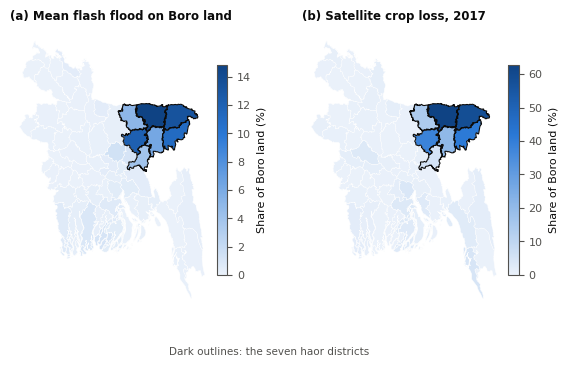

fig1_map.png


In [2]:
m = sh.merge(p.groupby("district").agg(a=("jrc_flash_boro", "mean"), b=("s1_flash_boro", "mean")).mean(axis=1).rename("flood").reset_index(), on="district")
m = m.merge(p[p.harvest_year == 2017][["district", "loss_share"]], on="district")
fig, axs = plt.subplots(1, 2, figsize=(6.9, 3.9))
for ax, col, title, lab in ((axs[0], "flood", "(a) Mean flash flood on Boro land", "Share of Boro land (%)"),
                            (axs[1], "loss_share", "(b) Satellite crop loss, 2017", "Share of Boro land (%)")):
    d = m.assign(v=m[col] * 100)
    d.plot(column="v", ax=ax, cmap=SEQ, edgecolor=SURF, linewidth=0.3, vmin=0, legend=True,
           legend_kwds=dict(shrink=0.7, label=lab, pad=0.01))
    d[d.district.isin(HAOR)].boundary.plot(ax=ax, color=INK, linewidth=0.8)
    ax.set_axis_off()
    panel_label(ax, title)
fig.text(0.5, 0.02, "Dark outlines: the seven haor districts", ha="center", color=MUTED, fontsize=7.5)
save(fig, "fig1_map.png")

## Figure 2: few events, and a coverage break

Panel (a) shows how much of the flood variation left after removing district and year means
comes from each year. Panel (b) shows Sentinel-1 scenes per haor district.

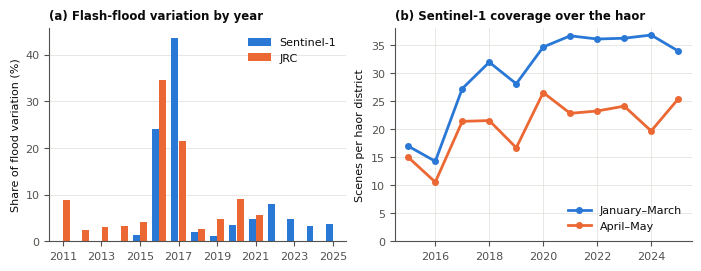

fig2_design.png


In [3]:
def shares(v):
    d = p.dropna(subset=[v]).copy()
    d["x"] = d[v] * 100
    d["r"] = d.x - d.groupby("district").x.transform("mean") - d.groupby("harvest_year").x.transform("mean") + d.x.mean()
    return d.groupby("harvest_year").r.apply(lambda s: (s ** 2).sum()) / (d.r ** 2).sum() * 100


fig, axs = plt.subplots(1, 2, figsize=(6.9, 2.6), constrained_layout=True)
ys = list(range(2011, 2026))
for i, (v, lab, col) in enumerate((("s1_flash_flood", "Sentinel-1", "#2a78d6"), ("jrc_flash_flood", "JRC", "#eb6834"))):
    s = shares(v).reindex(ys)
    axs[0].bar(np.array(ys) + (i - 0.5) * 0.38, s.values, width=0.36, color=col, label=lab)
axs[0].set_ylabel("Share of flood variation (%)")
axs[0].set_xticks(ys[::2])
axs[0].grid(axis="x", visible=False)
axs[0].legend(loc="upper right")
panel_label(axs[0], "(a) Flash-flood variation by year")
h = p[p.district.isin(HAOR) & p.harvest_year.ge(2015)].groupby("harvest_year")[["s1_scenes_dry", "s1_scenes_flash"]].mean()
axs[1].plot(h.index, h.s1_scenes_dry, color="#2a78d6", lw=2, marker="o", ms=4, label="January–March")
axs[1].plot(h.index, h.s1_scenes_flash, color="#eb6834", lw=2, marker="o", ms=4, label="April–May")
axs[1].set_ylabel("Scenes per haor district")
axs[1].set_ylim(0, None)
axs[1].legend(loc="lower right")
panel_label(axs[1], "(b) Sentinel-1 coverage over the haor")
save(fig, "fig2_design.png")

## Figure 3: harvested area, yield and production, year by year

Each point compares haor districts with all others, relative to 2015, on one shared scale.
Flood years are shaded. Intervals are clustered by district and can be too narrow with few
treated districts.

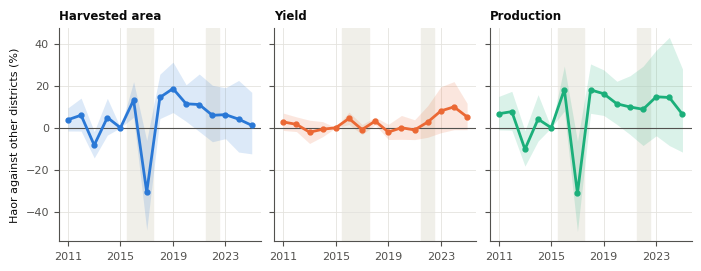

fig3_by_year.png


In [4]:
ev = pd.read_csv(OUT / "table_haor_by_year.csv")
fig, axs = plt.subplots(1, 3, figsize=(6.9, 2.6), sharey=True, constrained_layout=True)
for ax, o in zip(axs, COL):
    d = ev[ev.outcome == o].sort_values("year")
    for t in (2016, 2017, 2022):
        ax.axvspan(t - 0.5, t + 0.5, color="#f0efe9", zorder=0)
    lo, hi = 100 * (np.exp(d.b - 1.96 * d.se) - 1), 100 * (np.exp(d.b + 1.96 * d.se) - 1)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.fill_between(d.year, lo, hi, color=COL[o], alpha=0.16, lw=0)
    ax.plot(d.year, d.pct, color=COL[o], lw=2, marker="o", ms=3.5)
    ax.set_xticks([2011, 2015, 2019, 2023])
    panel_label(ax, o)
axs[0].set_ylabel("Haor against other districts (%)")
save(fig, "fig3_by_year.png")

## Figure 4: the 2017 flood across all districts

Panel (a) sets satellite crop loss against BBS harvested area. Panel (b) sets the flood
against BBS yield. Changes are from the mean of 2015 and 2018.

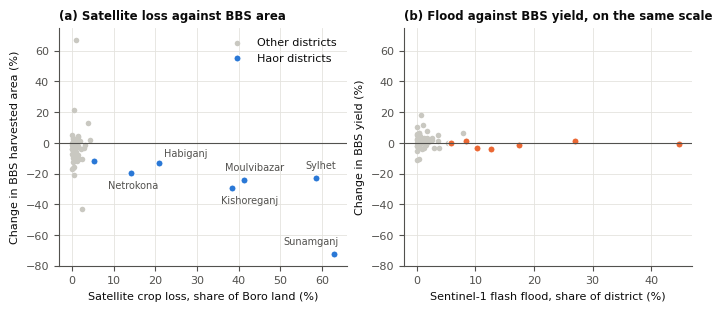

fig4_event_2017.png


In [5]:
e = pd.read_csv(OUT / "table_event_2017.csv")
fig, axs = plt.subplots(1, 2, figsize=(6.9, 3.0), constrained_layout=True)
ax = axs[0]
ax.axhline(0, color=MUTED, lw=0.8)
o = e[~e.district.isin(HAOR)]
h = e[e.district.isin(HAOR)]
ax.scatter(o.loss_share * 100, o.area_ha_chg_pct, s=16, color="#c9c8c1", label="Other districts", linewidths=0)
ax.scatter(h.loss_share * 100, h.area_ha_chg_pct, s=26, color=COL["Harvested area"], label="Haor districts", edgecolor=SURF, linewidth=0.8)
OFFSET = {"Kishoreganj": (-8, -11), "Moulvibazar": (-14, 7), "Netrokona": (-16, -11), "Habiganj": (4, 5), "Sylhet": (-8, 7), "Sunamganj": (-36, 7)}
for r in h.nlargest(6, "loss_share").itertuples():
    ax.annotate(r.district, (r.loss_share * 100, r.area_ha_chg_pct), xytext=OFFSET[r.district], textcoords="offset points", fontsize=7, color=MUTED)
ax.set_ylim(-80, 75)
ax.set_xlabel("Satellite crop loss, share of Boro land (%)")
ax.set_ylabel("Change in BBS harvested area (%)")
ax.legend(loc="upper right")
panel_label(ax, "(a) Satellite loss against BBS area")
ax = axs[1]
ax.axhline(0, color=MUTED, lw=0.8)
ax.scatter(o.s1_flash_flood * 100, o.yield_t_ha_chg_pct, s=16, color="#c9c8c1", linewidths=0)
ax.scatter(h.s1_flash_flood * 100, h.yield_t_ha_chg_pct, s=26, color=COL["Yield"], edgecolor=SURF, linewidth=0.8)
ax.set_ylim(-80, 75)
ax.set_xlabel("Sentinel-1 flash flood, share of district (%)")
ax.set_ylabel("Change in BBS yield (%)")
panel_label(ax, "(b) Flood against BBS yield, on the same scale")
save(fig, "fig4_event_2017.png")

## Figure 5: how the flash-flood estimates hold up

Each row reruns the main model with one change. Points are effects per 10 points of flood,
with 95 % clustered intervals, which can be too narrow here. Shaded bands mark the
±2 % range used for a negligible yield effect.

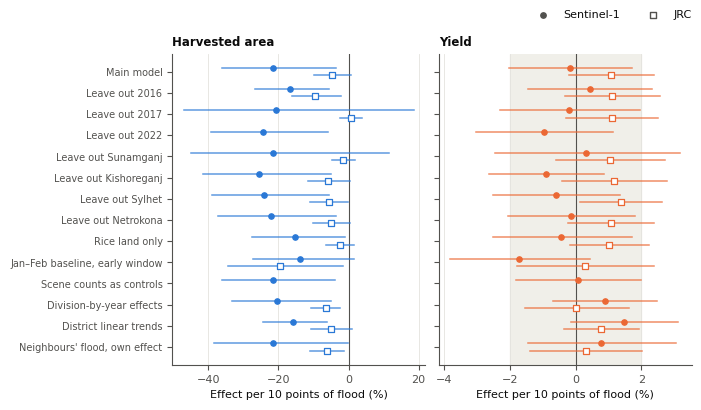

fig5_checks.png


In [6]:
ck = pd.read_csv(OUT / "table_checks.csv")
m = pd.read_csv(OUT / "table_main.csv")
order = ["Leave out 2016", "Leave out 2017", "Leave out 2022", "Leave out Sunamganj", "Leave out Kishoreganj", "Leave out Sylhet", "Leave out Netrokona",
         "Rice land only", "January-February baseline, early window", "Scene counts as controls",
         "Division-by-year effects", "District linear trends", "Neighbours' flood, own effect"]
fig, axs = plt.subplots(1, 2, figsize=(6.9, 4.0), sharey=True, constrained_layout=True)
for ax, o in zip(axs, ("Harvested area", "Yield")):
    if o == "Yield":
        ax.axvspan(-2, 2, color="#f0efe9", zorder=0)
    ax.axvline(0, color=MUTED, lw=0.8)
    for off, (src, mk) in zip((-0.17, 0.17), (("Sentinel-1", "o"), ("JRC", "s"))):
        rows = [("Main model", m[(m.source == src) & (m.flood == "flash") & (m.outcome == o)].iloc[0].to_dict())]
        for c in order:
            x = ck[(ck.check == c) & (ck.source == src) & (ck.outcome == o)]
            if len(x):
                rows.append((c, x.iloc[0].to_dict()))
        lab = {"Main model": 0, **{c: i + 1 for i, c in enumerate(order)}}
        for c, r in rows:
            y = lab[c] + off
            b, se = r["b"], r.get("se_cluster", np.nan)
            ax.plot([100 * (np.exp(b - 1.96 * se) - 1), 100 * (np.exp(b + 1.96 * se) - 1)], [y, y], color=COL[o], lw=1.1, alpha=0.75)
            ax.scatter(100 * (np.exp(b) - 1), y, marker=mk, s=15, color=COL[o] if src == "Sentinel-1" else SURF, edgecolor=COL[o], linewidth=0.9, zorder=3)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Effect per 10 points of flood (%)")
    panel_label(ax, o)
axs[0].set_yticks(range(len(order) + 1))
axs[0].set_yticklabels(["Main model"] + [c.replace("January-February baseline, early window", "Jan–Feb baseline, early window") for c in order], fontsize=7)
axs[0].invert_yaxis()
a = axs[0].scatter([], [], marker="o", s=15, color=MUTED, label="Sentinel-1")
b = axs[0].scatter([], [], marker="s", s=15, color=SURF, edgecolor=MUTED, label="JRC")
fig.legend(handles=[a, b], loc="outside upper right", ncol=2)
save(fig, "fig5_checks.png")

## Figure 6: normal and extreme floods

Effects are against the group below 1 %, with 95 % clustered intervals. District-years per
bin are shown under each label, Sentinel-1 first, because the largest bins hold very few.

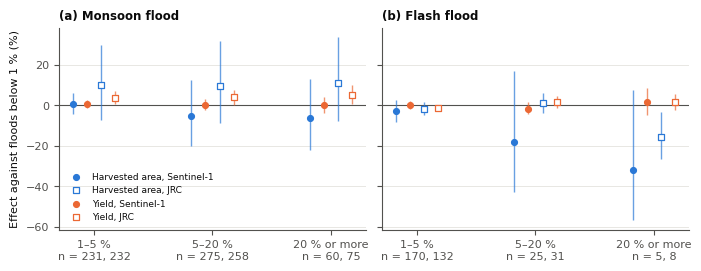

fig6_bins.png


In [7]:
b = pd.read_csv(OUT / "table_flood_bins.csv")
order_bins = ["1-5", "5-20", "20+"]
fig, axs = plt.subplots(1, 2, figsize=(6.9, 2.6), sharey=True, constrained_layout=True)
for ax, fl, title in zip(axs, ("monsoon", "flash"), ("(a) Monsoon flood", "(b) Flash flood")):
    ax.axhline(0, color=MUTED, lw=0.8)
    for i, o in enumerate(("Harvested area", "Yield")):
        for src, mk, off in (("Sentinel-1", "o", -0.12), ("JRC", "s", 0.12)):
            d = b[(b.flood == fl) & (b.outcome == o) & (b.source == src)].set_index("bin").reindex(order_bins)
            x = np.arange(3) + off + (i - 0.5) * 0.12
            lo, hi = 100 * (np.exp(d.b - 1.96 * d.se) - 1), 100 * (np.exp(d.b + 1.96 * d.se) - 1)
            ax.vlines(x, lo, hi, color=COL[o], lw=1.0, alpha=0.7)
            ax.scatter(x, d.pct, marker=mk, s=18, color=COL[o] if src == "Sentinel-1" else SURF, edgecolor=COL[o], linewidth=0.9, zorder=3, label=f"{o}, {src}")
    n = {s: b[(b.flood == fl) & (b.outcome == "Yield") & (b.source == s)].set_index("bin").n_in_bin for s in ("Sentinel-1", "JRC")}
    ax.set_xticks(range(3))
    ax.set_xticklabels([f"{lab}\nn = {n['Sentinel-1'][k]}, {n['JRC'][k]}" for k, lab in zip(order_bins, ("1–5 %", "5–20 %", "20 % or more"))])
    ax.grid(axis="x", visible=False)
    panel_label(ax, title)
axs[0].set_ylabel("Effect against floods below 1 % (%)")
axs[0].legend(fontsize=6.5, loc="lower left")
save(fig, "fig6_bins.png")

## Figure 7: risk index and how stable it is

Panel (a) maps the risk tier, with haor districts outlined. Panel (b) shows each of the top
15 districts' rank across every combination of choices. Hatched districts, starred in
panel (b), have a small Boro base, so their shares and instability are unreliable.

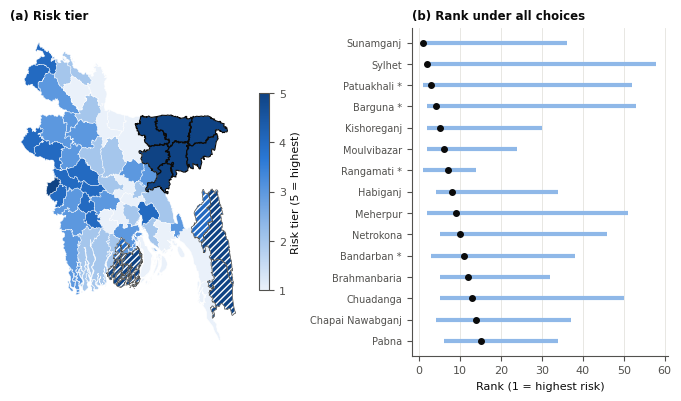

fig7_index.png


In [8]:
ix = pd.read_csv(OUT / "table_index.csv").rename(columns={"Unnamed: 0": "district"})
if "district" not in ix:
    ix = ix.rename(columns={ix.columns[0]: "district"})
m = sh.merge(ix, on="district")
fig, axs = plt.subplots(1, 2, figsize=(6.9, 3.9), gridspec_kw=dict(width_ratios=[1, 1]), constrained_layout=True)
ax = axs[0]
m.assign(v=6 - m.tier).plot(column="v", ax=ax, cmap=SEQ, edgecolor=SURF, linewidth=0.3, categorical=False, vmin=1, vmax=5,
                            legend=True, legend_kwds=dict(shrink=0.6, ticks=[1, 2, 3, 4, 5], label="Risk tier (5 = highest)"))
m[m.small_base].plot(ax=ax, facecolor="none", edgecolor=SURF, hatch="/////", linewidth=0)
m[m.small_base].boundary.plot(ax=ax, color=MUTED, linewidth=0.5)
m[m.district.isin(HAOR)].boundary.plot(ax=ax, color=INK, linewidth=0.8)
ax.set_axis_off()
panel_label(ax, "(a) Risk tier")
ax = axs[1]
t = ix.sort_values("rank").head(15).iloc[::-1]
y = np.arange(len(t))
ax.hlines(y, t.rank_p05, t.rank_p95, color="#8fb8e8", lw=3)
ax.scatter(t["rank"], y, s=16, color=INK, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([d + " *" if s else d for d, s in zip(t.district, t.small_base)], fontsize=7)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Rank (1 = highest risk)")
panel_label(ax, "(b) Rank under all choices")
save(fig, "fig7_index.png")